In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
from src.config import TEST_DIR, CV_DIR, DATA_PROCESSED

# Đọc danh sách tên các lớp và file kết quả dự đoán trên tập test
label_df = pd.read_csv(DATA_PROCESSED / "label_names.csv")
labels = label_df.squeeze("columns").tolist()

d = pd.read_csv(TEST_DIR / "final_predictions.csv")

# Chuyển mã số nhãn thành tên lớp để dễ đọc khi phân tích lỗi
label_map = dict(enumerate(labels))
d["lop_that"] = d["y_true"].map(label_map)
d["lop_du_doan"] = d["y_pred"].map(label_map)

# Đánh dấu các dòng dự đoán sai
d["sai"] = d["y_true"] != d["y_pred"]

so_mau_sai = int(d["sai"].sum())
tong_mau = len(d)
print("So mau sai:", so_mau_sai, "tren", tong_mau)

So mau sai: 32 tren 23585


In [2]:
# Lọc ra các mẫu bị dự đoán sai
df_sai = d[d["sai"]]

# Đếm số lần xuất hiện của từng cặp (lớp thật, lớp dự đoán sai) và sắp xếp giảm dần
cap = df_sai.groupby(["lop_that", "lop_du_doan"]).size()
cap = cap.sort_values(ascending=False)
cap = cap.rename("so_mau")
cap = cap.reset_index()

# Lưu bảng các cặp nhầm lẫn phổ biến ra file CSV
cap.to_csv(TEST_DIR / "top_confusions.csv", index=False)

# Hiển thị top 15 cặp bị nhầm nhiều nhất
cap.head(15)

,lop_that,lop_du_doan,so_mau
0,ARP_poisioning,Thing_Speak,11
1,Thing_Speak,ARP_poisioning,8
2,NMAP_UDP_SCAN,DDOS_Slowloris,2
3,ARP_poisioning,NMAP_TCP_scan,2
4,NMAP_UDP_SCAN,Thing_Speak,2
5,ARP_poisioning,DDOS_Slowloris,1
6,MQTT_Publish,Thing_Speak,1
7,NMAP_UDP_SCAN,ARP_poisioning,1
8,NMAP_XMAS_TREE_SCAN,ARP_poisioning,1
9,Thing_Speak,DDOS_Slowloris,1


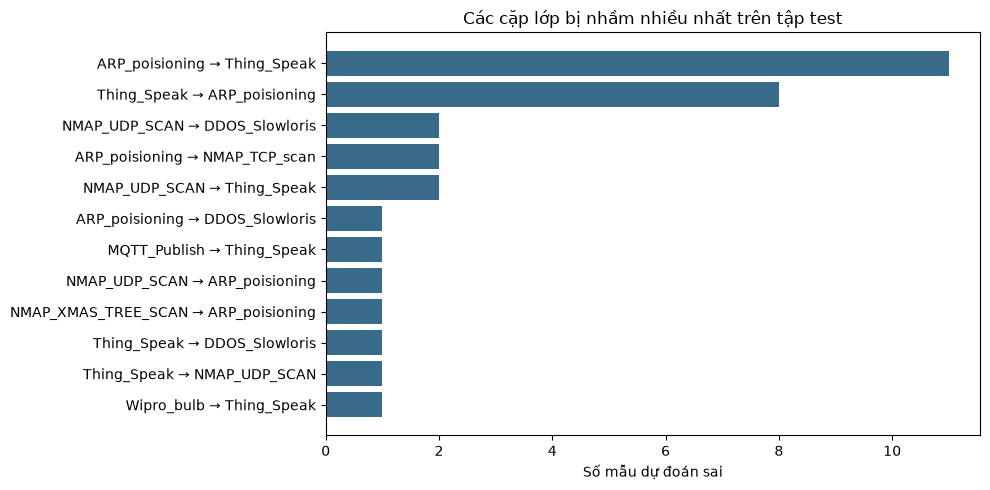

In [3]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

results = (Path('..') if Path.cwd().name == 'experiments' else Path('.')) / 'results'
errors = pd.read_csv(results / 'test/top_confusions.csv').nlargest(15, 'so_mau')
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(errors['lop_that'] + ' → ' + errors['lop_du_doan'], errors['so_mau'], color='#386A89')
ax.invert_yaxis()
ax.set(title='Các cặp lớp bị nhầm nhiều nhất trên tập test', xlabel='Số mẫu dự đoán sai')
fig.tight_layout()
(results / 'figures').mkdir(exist_ok=True)
fig.savefig(results / 'figures/top_confusions.png', dpi=300, bbox_inches='tight')
plt.show()

In [4]:
tom_tat = d.groupby("lop_that").agg(
    so_mau=("sai", "size"),
    so_sai=("sai", "sum"),
    proba_lop_that_tb=("proba_lop_that", "mean"),
)
tom_tat["ti_le_sai"] = tom_tat["so_sai"] / tom_tat["so_mau"]
tom_tat.round(4)

,so_mau,so_sai,proba_lop_that_tb,ti_le_sai
lop_that,,,,
ARP_poisioning,1525,14,0.9908,0.0092
DDOS_Slowloris,107,0,1.0000,0.0000
DOS_SYN_Hping,18018,0,1.0000,0.0000
MQTT_Publish,828,1,0.9988,0.0012
Metasploit_Brute_Force_SSH,7,0,1.0000,0.0000
NMAP_FIN_SCAN,6,0,1.0000,0.0000
NMAP_OS_DETECTION,400,0,1.0000,0.0000
NMAP_TCP_scan,200,0,1.0000,0.0000
NMAP_UDP_SCAN,517,5,0.9905,0.0097


In [5]:
# Tách riêng tập các mẫu dự đoán sai và tập các mẫu dự đoán đúng
sai = d[d["sai"]]
dung = d[d["sai"] == False]

# Tính xác suất dự đoán trung bình của từng nhóm
conf_sai_tb = sai["proba_du_doan"].mean()
conf_dung_tb = dung["proba_du_doan"].mean()

# Tính tỷ lệ các mẫu sai nhưng có xác suất dự đoán lớn hơn 0.9
cao_tin_cay_nhung_sai = sai["proba_du_doan"] > 0.9
ti_le_sai_tin_cao = cao_tin_cay_nhung_sai.mean()

print("Do tin cay trung binh cua mau sai:", round(conf_sai_tb, 3))
print("Do tin cay trung binh cua mau dung:", round(conf_dung_tb, 3))
print("Ti le mau sai ma do tin cay tren 0.9:", round(ti_le_sai_tin_cao, 3))

Do tin cay trung binh cua mau sai: 0.865
Do tin cay trung binh cua mau dung: 1.0
Ti le mau sai ma do tin cay tren 0.9: 0.594


In [6]:
# Đọc kết quả từng lớp từ CV (bảng có 2 tầng header) và chọn riêng mô hình hgb_N1_balanced
cv_all = pd.read_csv(CV_DIR / "finalists_per_class.csv", header=[0, 1], index_col=0)
cv = cv_all["hgb_N1_balanced"]

# Đọc kết quả từng lớp trên tập test và đặt tên lớp làm index để dễ đối chiếu
test = pd.read_csv(TEST_DIR / "final_per_class_ci.csv")
test = test.set_index("lop")

# Ghép các cột recall và precision của CV và test vào cùng một bảng so sánh
so_sanh = pd.DataFrame({
    "recall_cv": cv["recall"],
    "recall_test": test["recall"],
    "precision_cv": cv["precision"],
    "precision_test": test["precision"],
})

# Tính độ chênh lệch recall giữa tập test và CV
so_sanh["chenh_recall"] = so_sanh["recall_test"] - so_sanh["recall_cv"]

# Làm tròn 3 chữ số thập phân để dễ đọc
so_sanh = so_sanh.round(3)
so_sanh

,recall_cv,recall_test,precision_cv,precision_test,chenh_recall
ARP_poisioning,0.993,0.991,0.987,0.993,-0.002
DDOS_Slowloris,0.993,1.000,0.993,0.964,0.007
DOS_SYN_Hping,1.000,1.000,1.000,1.000,0.000
MQTT_Publish,0.998,0.999,1.000,1.000,0.001
Metasploit_Brute_Force_SSH,0.724,1.000,0.808,1.000,0.276
NMAP_FIN_SCAN,0.818,1.000,0.900,1.000,0.182
NMAP_OS_DETECTION,1.000,1.000,1.000,1.000,0.000
NMAP_TCP_scan,0.999,1.000,0.999,0.990,0.001
NMAP_UDP_SCAN,0.989,0.990,0.992,0.998,0.001
NMAP_XMAS_TREE_SCAN,0.998,0.998,0.999,1.000,-0.000
